# 01 — Exploratory Data Analysis

---

## Context and Research Question

The yield curve represents bond yields across different maturities. Its evolution reflects market expectations regarding monetary policy, inflation, and economic conditions.

> *This project focuses on **forecasting the US Treasury yield curve using Machine Learning**. The objective is to compare forecasting performance across short-, medium-, and long-term maturities to determine whether some maturities are more predictable than others.*

## Data Source

The analysis is based on historical US Treasury yields obtained from the Federal Reserve Economic Data (FRED) database.

| **Characteristic** | **Description** |
|---|---|
| Source | FRED (Federal Reserve Bank of St. Louis) |
| Market | US Treasury Securities |
| Period | January 2005 – November 2026 |
| Frequency | Daily |
| Unit | Percent (%) |
| Maturities | 3M, 6M, 1Y, 2Y, 3Y, 5Y, 7Y, 10Y, 20Y, 30Y |
| Main comparison | 3M vs 10Y vs 30Y |

## 1. Dataset

The dataset covers **ten maturities ranging from 3 months to 30 years**, with yields expressed in **percent (%)** at a **daily frequency**.

All statistics presented below are calculated directly from the raw CSV files stored in the `data/` directory.

In [1]:
# Install the FRED API librairy 
pip install fredapi

Note: you may need to restart the kernel to use updated packages.


Impossible d’analyser la valeur spécifiée dans une clé de Registre AutoRun.


In [1]:
# Libraries usefull for the rest of the project.
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
from fredapi import Fred
from scipy.stats import skew, kurtosis

In [2]:
api_key = 'ee2f9e33f36fdf884e7039bd0f313d31'
fred = Fred(api_key=api_key)

series = {"1M": "DGS1MO","3M": "DGS3MO","6M": "DGS6MO", "1Y": "DGS1",
          "5Y": "DGS5", "10Y": "DGS10", "20Y": "DGS20", "30Y": "DGS30"}

def download_data(data_series, start_date, output_file):
    
    data = pd.DataFrame()
    for maturity, series_id in data_series.items():
        data[maturity] = fred.get_series(series_id, observation_start=start_date)
        
    data.index.name = "Date"
    print(f"Study period: {data.index.min():%d/%m/%Y} to {data.index.max():%d/%m/%Y}")
    print(f"Observations: {len(data):,} | Maturities: {data.shape[1]}")
    print("Series:", ", ".join(data.columns))
    
    data.to_csv(output_file)

    return data

In [3]:
data = download_data(series, "2016-01-01", 'yield_curve.csv')
display(data.head(10))

Study period: 01/01/2016 to 17/11/2026
Observations: 2,838 | Maturities: 8
Series: 1M, 3M, 6M, 1Y, 5Y, 10Y, 20Y, 30Y


,1M,3M,6M,1Y,5Y,10Y,20Y,30Y
Date,,,,,,,,
2016-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-01-04,0.17,0.22,0.49,0.61,1.73,2.24,2.64,2.98
2016-01-05,0.20,0.20,0.49,0.68,1.73,2.25,2.67,3.01
2016-01-06,0.21,0.21,0.47,0.67,1.65,2.18,2.59,2.94
2016-01-07,0.20,0.20,0.46,0.66,1.61,2.16,2.56,2.92
2016-01-08,0.20,0.20,0.45,0.64,1.57,2.13,2.55,2.91
2016-01-11,0.19,0.21,0.48,0.63,1.58,2.17,2.59,2.96
2016-01-12,0.22,0.21,0.47,0.62,1.55,2.12,2.51,2.89
2016-01-13,0.22,0.22,0.46,0.60,1.51,2.08,2.47,2.85


## 2. Missing Values

,Available observations,Missing values,Missing percentage (%)
1M,2719,119,4.19
3M,2719,119,4.19
6M,2719,119,4.19
1Y,2719,119,4.19
5Y,2719,119,4.19
10Y,2719,119,4.19
20Y,2719,119,4.19
30Y,2719,119,4.19


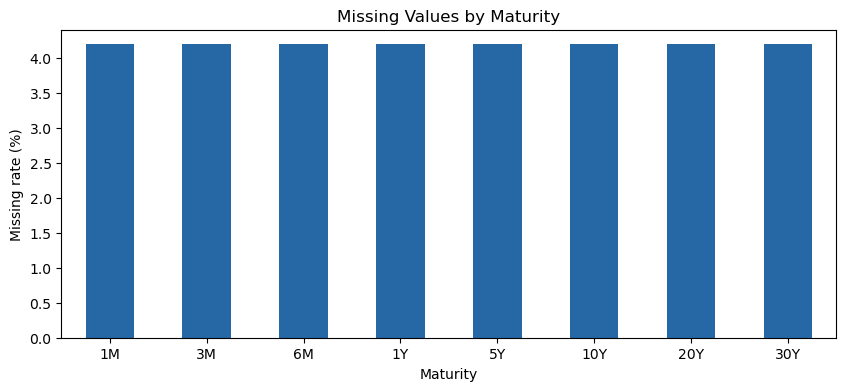

In [4]:
# Missing values by maturity

def compute_missing_val(df):
    # Missing values summary
    missing = pd.DataFrame({"Available observations": df.notna().sum(),"Missing values": df.isna().sum(),
                            "Missing percentage (%)": (df.isna().mean() * 100).round(2)})

    display(missing)

    ax = missing["Missing percentage (%)"].plot.bar(figsize=(10, 4), color="#2668A5")
    ax.set(title="Missing Values by Maturity", xlabel="Maturity",ylabel="Missing rate (%)")
    plt.xticks(rotation=0)

compute_missing_val(data)

In [6]:
def compare_missing_dates(df):
    
    missing_dates = {}
    for col in df.columns:
        missing_dates[col] = set(data.index[data[col].isna()])
    
    
    maturities = df.columns
    intersection_matrix = pd.DataFrame(index=maturities,columns=maturities, dtype=int)
    for col1 in maturities:
        for col2 in maturities:
            intersection_matrix.loc[col1, col2] = len(missing_dates[col1].intersection(missing_dates[col2]))
    print(intersection_matrix)


def identify_missing_dates(df,col) :

    missing_df_dates = df[df[col].isna()].copy()
    missing_df_dates["Day"] = missing_df_dates.index.day_name()
    missing_df_dates = missing_df_dates[missing_df_dates.index.weekday < 5] # filtration on week days (monday=0)
  
    return missing_df_dates[[col,'Day']]

compare_missing_dates(data)
missing_dates = identify_missing_dates(data, '3M')
# In our case we see that the missing days are all the same. Now we must see why they are missing and if it's linked to something special. 
# We see that this corresponds to day off  (2016-01-01, 2026-05-25)...

        1M     3M     6M     1Y     5Y    10Y    20Y    30Y
1M   119.0  119.0  119.0  119.0  119.0  119.0  119.0  119.0
3M   119.0  119.0  119.0  119.0  119.0  119.0  119.0  119.0
6M   119.0  119.0  119.0  119.0  119.0  119.0  119.0  119.0
1Y   119.0  119.0  119.0  119.0  119.0  119.0  119.0  119.0
5Y   119.0  119.0  119.0  119.0  119.0  119.0  119.0  119.0
10Y  119.0  119.0  119.0  119.0  119.0  119.0  119.0  119.0
20Y  119.0  119.0  119.0  119.0  119.0  119.0  119.0  119.0
30Y  119.0  119.0  119.0  119.0  119.0  119.0  119.0  119.0


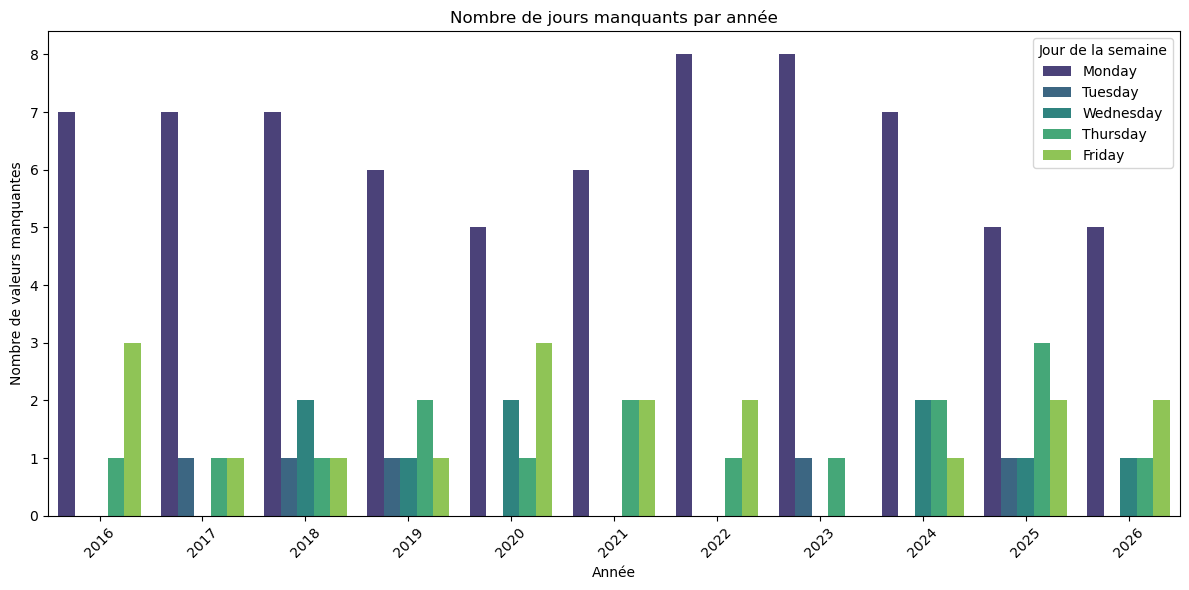

In [7]:
def hist_missing_days(df_missing) : 
    df_missing["Year"] = df_missing.index.year
    day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
    plt.figure(figsize=(12, 6))
    sns.countplot(data= df_missing, x="Year", hue="Day",order=sorted(df_missing["Year"].unique()),hue_order=day_order,palette="viridis")

    plt.title("Nombre de jours manquants par année")
    plt.xlabel("Année")
    plt.ylabel("Nombre de valeurs manquantes")
    plt.legend(title="Jour de la semaine")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    
hist_missing_days(missing_dates)

The analysis identifies **XXX missing dates**, shared across all XXX maturities. These gaps are mainly explained by the US holiday calendar:

- **XXX federal holidays**;
- **XXX Good Fridays**;
- **XXX exceptional market closures**, related to Hurricane Sandy in 2012 and the national day of mourning in 2018.

Since all XXX maturities have missing values on the same dates, these gaps appear to be related to the yield publication calendar rather than issues specific to individual maturities.

For the next steps of the project, these dates can be removed during preprocessing, as no yields are available for any maturity.

## 3. Descriptive Statistics

In [8]:
# Due to the analysis we ran previously on the missing dates, we can exclude them without issues.
new_data = data.dropna(axis=0 , how = 'all')

In [9]:
new_data.info()
stats = new_data.describe().T[["count", "mean", "std", "min", "50%", "max"]]
stats.columns = ["Count", "Mean (%)", "Std (%)", "Min (%)", "Median (%)", "Max (%)"]
display(stats.round(2))

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2719 entries, 2016-01-04 to 2026-11-17
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   1M      2719 non-null   float64
 1   3M      2719 non-null   float64
 2   6M      2719 non-null   float64
 3   1Y      2719 non-null   float64
 4   5Y      2719 non-null   float64
 5   10Y     2719 non-null   float64
 6   20Y     2719 non-null   float64
 7   30Y     2719 non-null   float64
dtypes: float64(8)
memory usage: 191.2 KB


,Count,Mean (%),Std (%),Min (%),Median (%),Max (%)
1M,2719.0,2.31,1.96,0.00,1.94,6.02
3M,2719.0,2.38,1.94,0.00,1.99,5.63
6M,2719.0,2.44,1.88,0.02,2.12,5.61
1Y,2719.0,2.44,1.77,0.04,2.30,5.49
5Y,2719.0,2.59,1.36,0.19,2.61,5.09
10Y,2719.0,2.84,1.24,0.52,2.77,5.31
20Y,2719.0,3.21,1.23,0.87,2.91,5.71
30Y,2719.0,3.27,1.12,0.99,3.04,5.67


We can see that average yields increase with maturity, from **XXX for 3M to XXX% for 30Y**. On the other hand, the standard deviation decreases from **XXX to XXX percentage points**, showing that short-term yield levels have varied more over the period.

These results show some differences between short- and long-term maturities. For our project, it will be interesting to see whether these differences also affect how accurately we can predict yields.

## 4. Historical Evolution

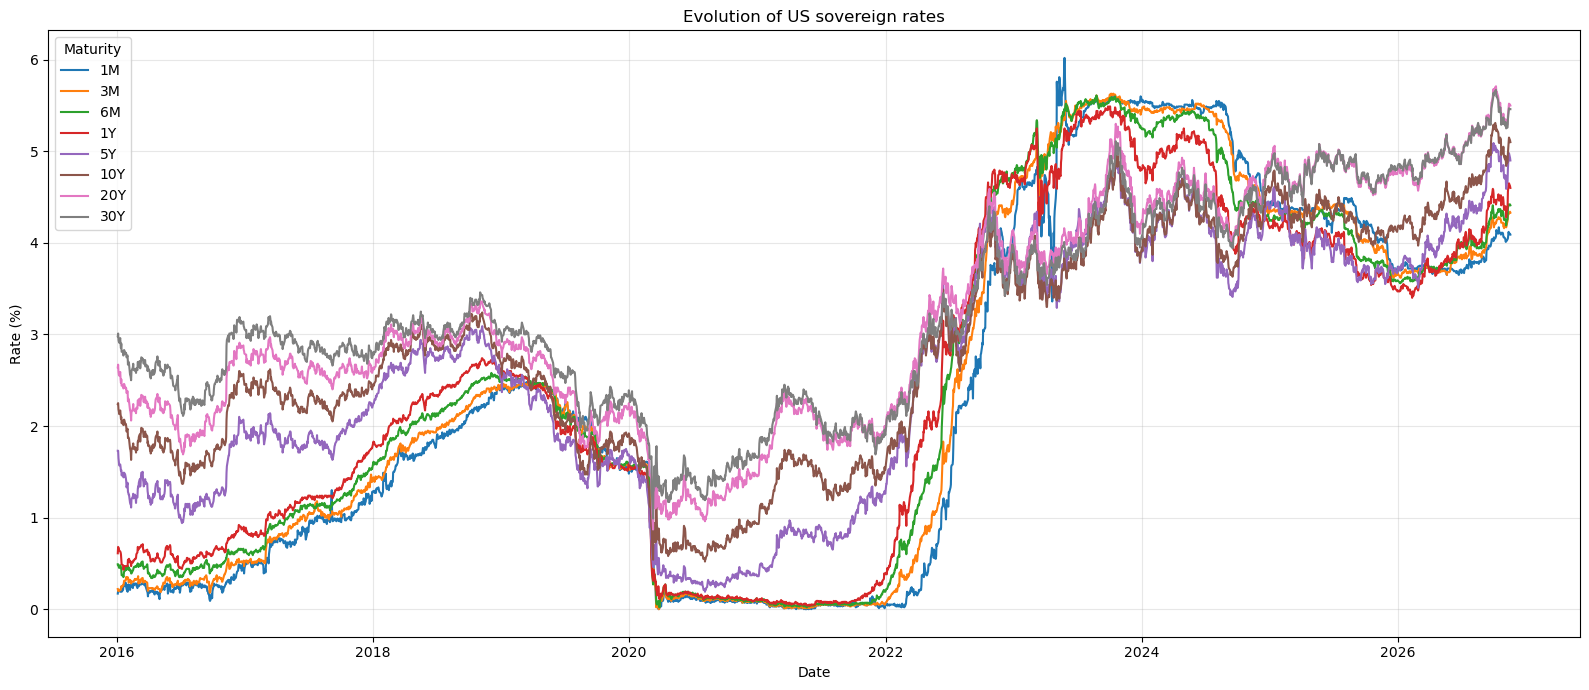

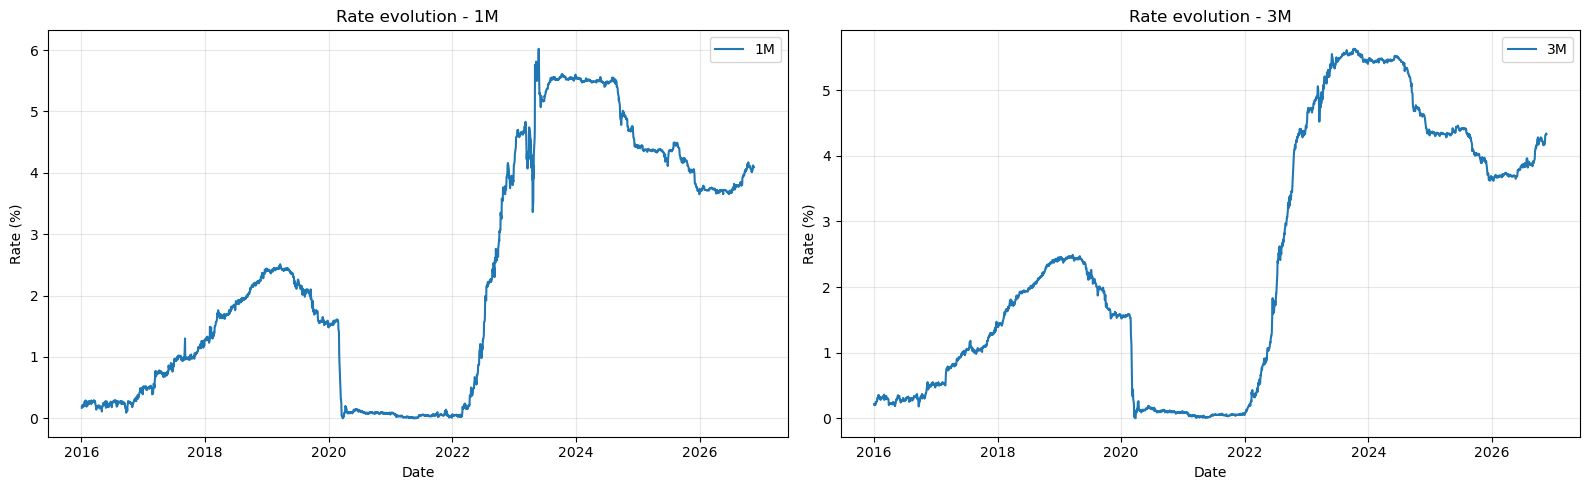

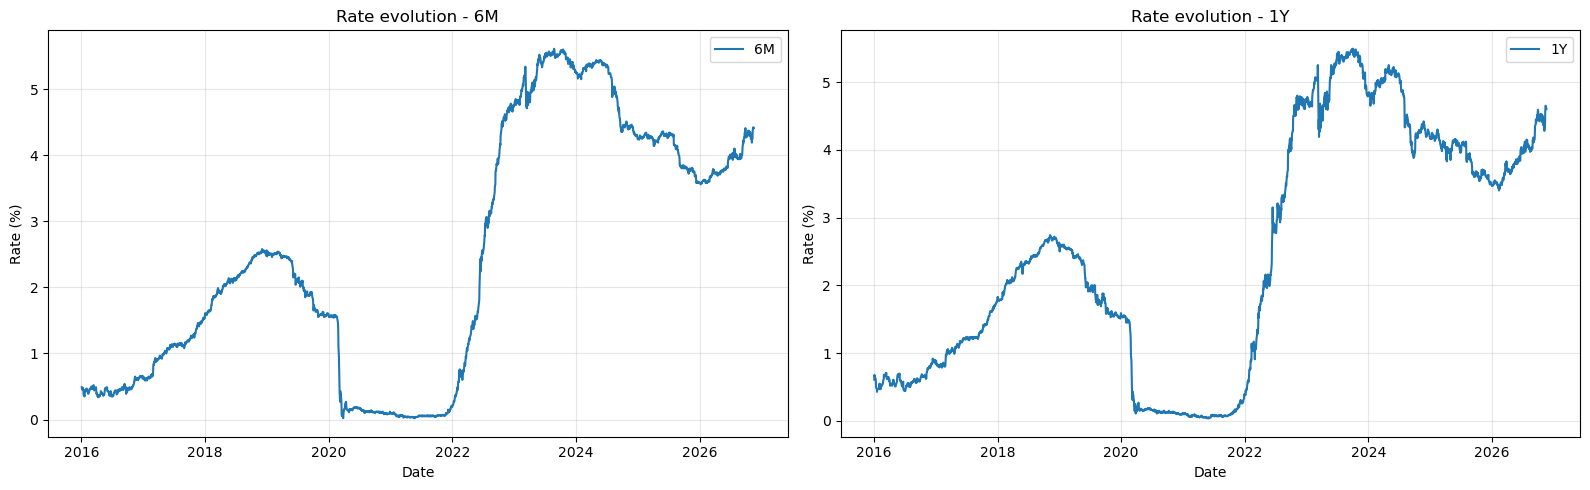

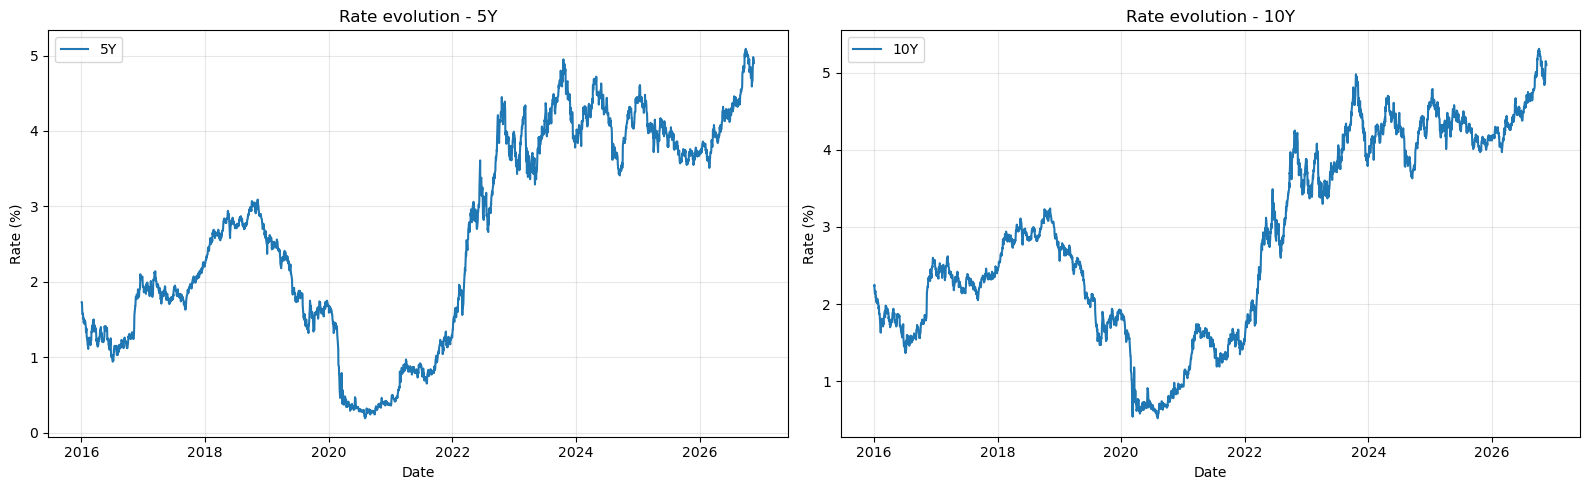

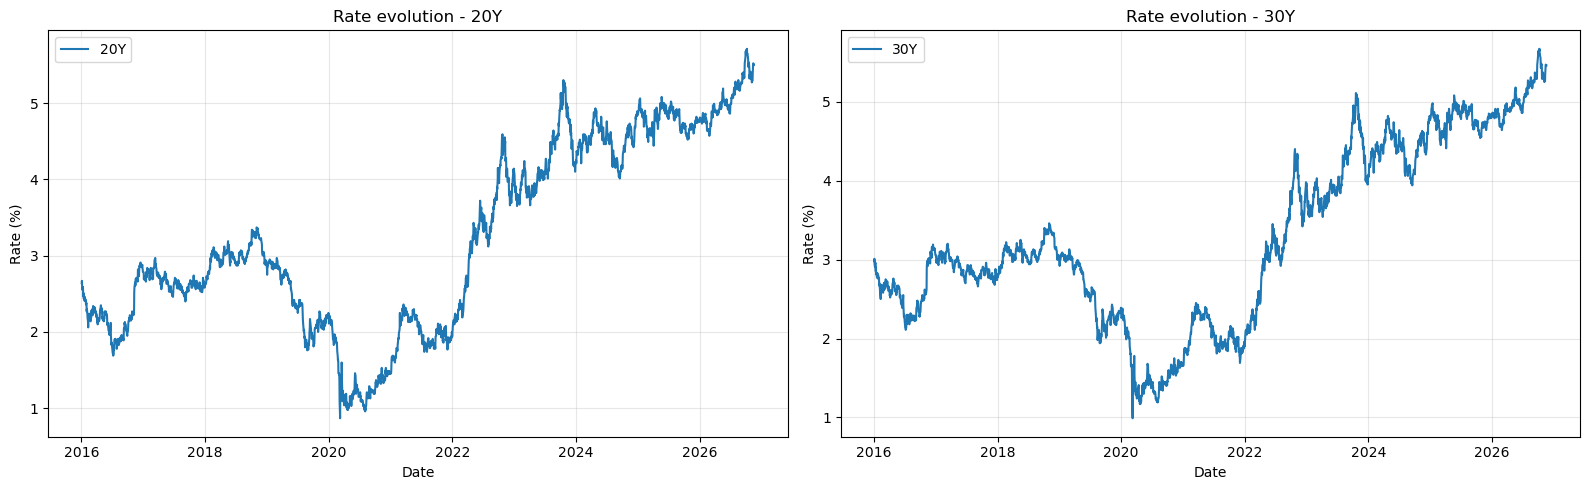

In [10]:
def plot_yield_curves(df):

    # Plot all yield curves together
    plt.figure(figsize=(16, 7))

    for col in df.columns:
        plt.plot(df.index, df[col], label=col)

    plt.title("Evolution of US sovereign rates")
    plt.xlabel("Date")
    plt.ylabel("Rate (%)")
    plt.legend(title="Maturity")
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    for i in range(0, len(df.columns), 2):
        fig, axes = plt.subplots(1, 2, figsize=(16, 5))
        for j, ax in enumerate(axes):
            if i + j < len(df.columns):
                col = df.columns[i + j]

                ax.plot(df.index, df[col], label=col)
                ax.set_title(f"Rate evolution - {col}")
                ax.set_xlabel("Date")
                ax.set_ylabel("Rate (%)")
                ax.legend()
                ax.grid(alpha=0.3)

        plt.tight_layout()
        plt.show()

plot_yield_curves(new_data)


# Need to be modified accordingly with the time period choosen
We can see large falls around the 2008 financial crisis and the 2020 pandemic, followed by a strong rise in 2022–2023 as the Fed tightened monetary policy to fight inflation.

The 3M yield reacts strongly to changes in short-term interest rates, while 10Y and 30Y yields also reflect longer-term expectations and term premiums. Sometimes the 3M rate rises above the 10Y or 30Y rate, showing an inverted yield curve.

## 5. Distributions

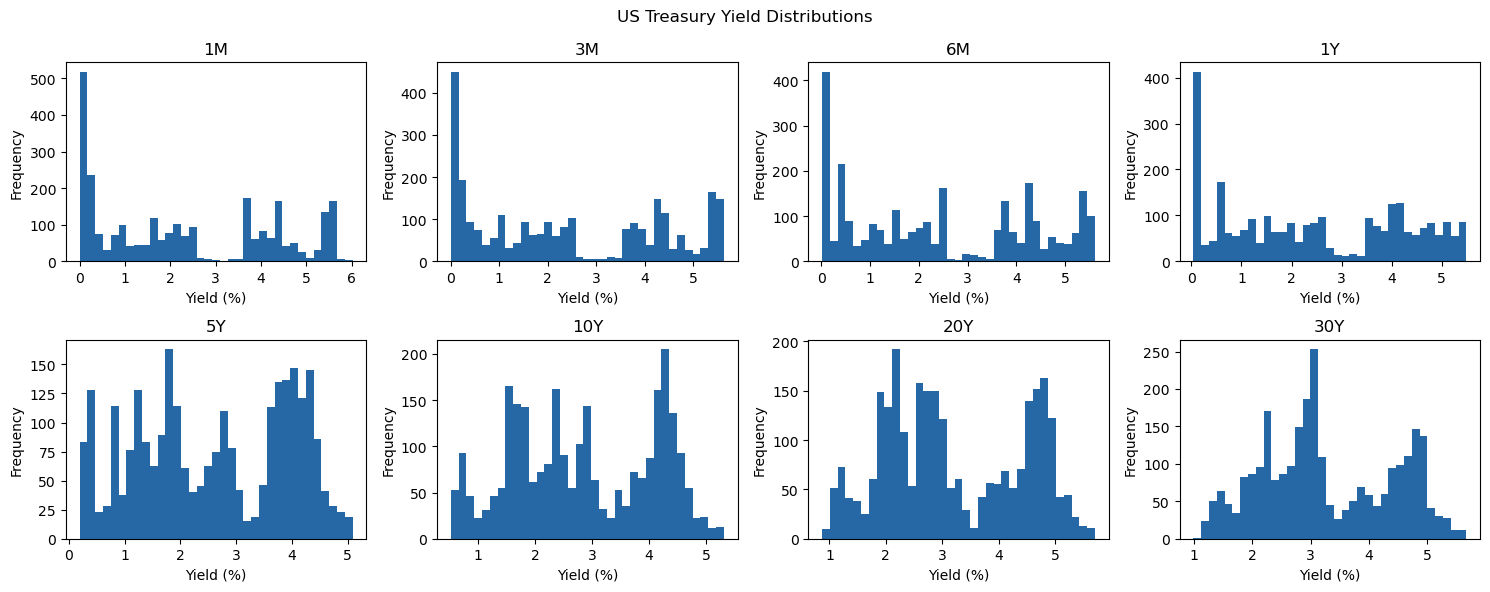

,Skewness,Kurtosis
1M,0.32,-1.38
3M,0.28,-1.41
6M,0.22,-1.41
1Y,0.14,-1.40
5Y,-0.07,-1.31
10Y,-0.01,-1.21
20Y,0.15,-1.24
30Y,0.17,-1.08


In [19]:
# Yield distributions
def plot_yield_distributions(df, n_rows, n_cols):

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3 * n_rows))
    axes = np.array(axes).flatten()

    for ax, maturity in zip(axes, df.columns):
        ax.hist(df[maturity].dropna(), bins=35, color="#2668A5")
        ax.set(title=maturity, xlabel="Yield (%)", ylabel="Frequency")

    # Hide unused subplots
    for ax in axes[len(df.columns):]:
        ax.set_visible(False)

    fig.suptitle("US Treasury Yield Distributions")
    plt.tight_layout()
    plt.show()

    # Skewness and Kurtosis
    stats = pd.DataFrame({"Skewness": df.skew().round(2), "Kurtosis": df.kurt().round(2)})
    display(stats)

plot_yield_distributions(new_data, n_rows=2, n_cols=4)

# Ajouter pour les rendements car les résultats sont intéressants

Short-term yields are heavily concentrated around 0%, mainly due to the accommodative monetary policies implemented after the 2008 and 2020 crises. In contrast, long-term yields show more spread-out distributions with several peaks, reflecting different interest rate regimes over the period studied.

Finally, skewness decreases with maturity, from **+0.61 for 3M to −0.25 for 30Y**. These differences show that yield distributions vary across maturities and do not all follow a normal distribution.

**Comments need to be aligned with the time period we choose**

## 6. Correlations

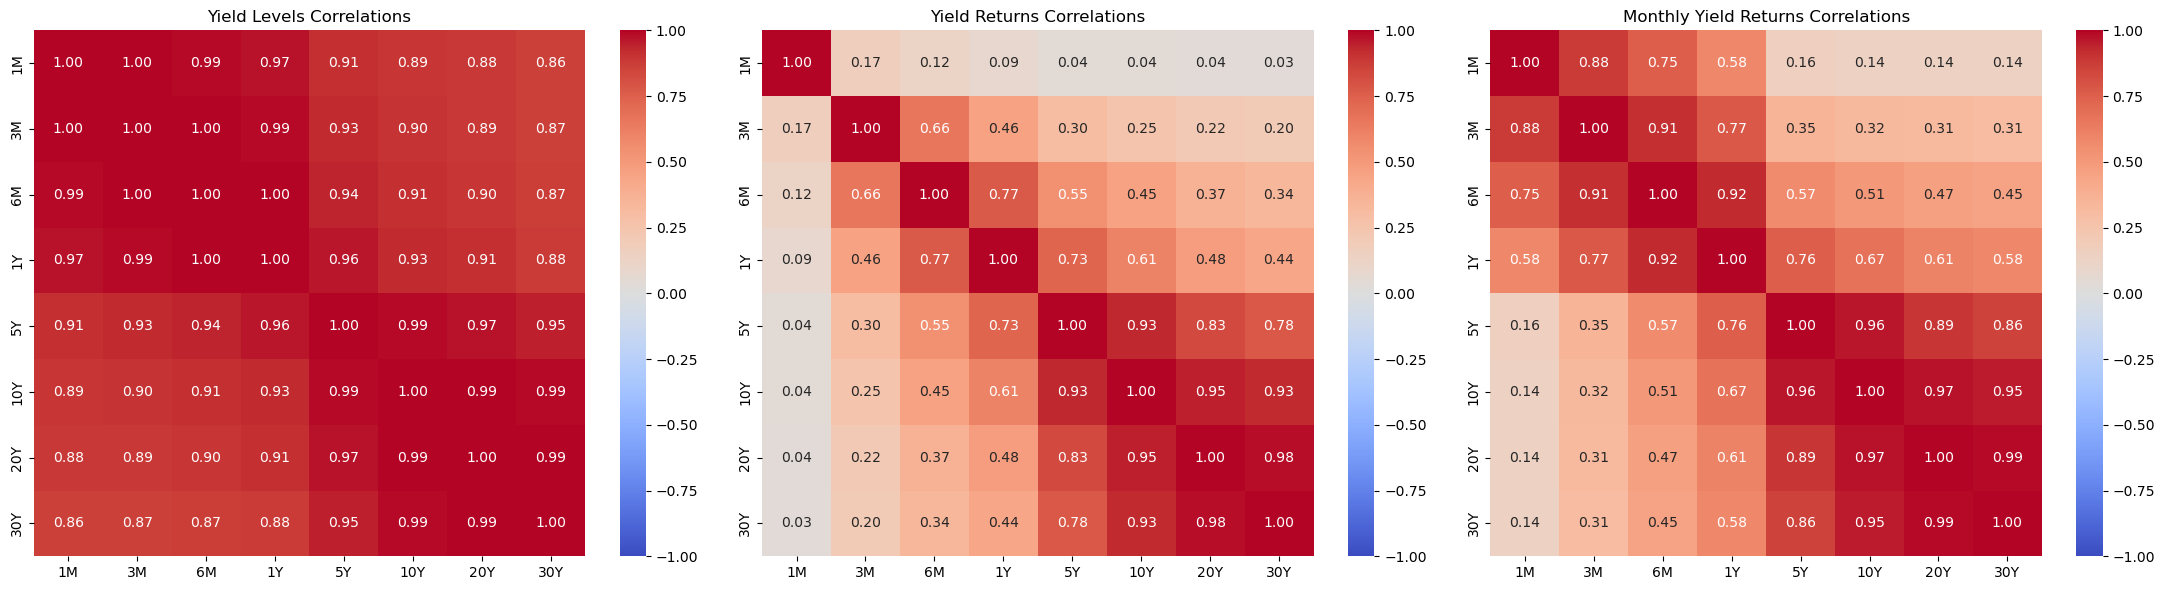

In [17]:
# Monthly yield changes 
def plot_yield_correlations(df):

    # day to day return 
    returns = df.diff().dropna()*100
    # Monthly yield changes
    monthly = df.dropna().resample("ME").last().dropna()
    # Exclude current incomplete month
    if monthly.index[-1].to_period("M") == pd.Timestamp.today().to_period("M"):
        monthly = monthly.iloc[:-1]
    changes = monthly.diff().dropna() * 100

    # Correlation matrices
    corr_levels = df.corr()
    corr_returns = returns.corr()
    corr_changes_monthly = changes.corr()

    # Plot heatmaps side by side
    fig, axes = plt.subplots(1, 3, figsize=(22, 6))

    sns.heatmap(corr_levels, annot=True,  cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, ax=axes[0])
    axes[0].set_title("Yield Levels Correlations")

    sns.heatmap(corr_returns, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, ax=axes[1])
    axes[1].set_title("Yield Returns Correlations")

    sns.heatmap(corr_changes_monthly, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, ax=axes[2])
    axes[2].set_title("Monthly Yield Returns Correlations")
    
    plt.tight_layout()
    plt.show()


plot_yield_correlations(new_data)

We can see that US Treasury yields are generally highly correlated when looking at their levels, as they follow similar economic trends.

However, when looking at monthly changes, the differences become more noticeable. For example, the correlation between 3M and 30Y drops from **0.6 to 0.2**, while it remains around **0.9 between 3M and 6M**.

This suggests that maturities close to each other tend to move in a similar way, unlike maturities that are further apart. For our project, it will be interesting to see whether these differences affect how predictable interest rates are.

**Text need be changed accordingly with the new udpates**


## 7. Extreme Changes (Outliers)

,Extreme Changes (> 3σ)
1M,4
3M,3
6M,3
1Y,2
5Y,0
10Y,0
20Y,0
30Y,0


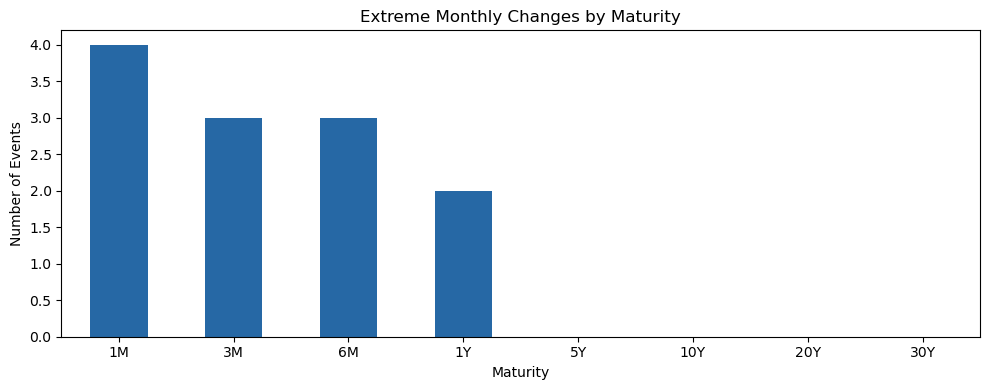

In [20]:
def detect_outliers(df) :
    
    monthly = df.dropna().resample("ME").last().dropna()
    # Exclude current incomplete month
    if monthly.index[-1].to_period("M") == pd.Timestamp.today().to_period("M"):
        monthly = monthly.iloc[:-1]
    monthly_changes = monthly.diff().dropna() * 100

    # Detect extreme monthly changes (> 3 standard deviations)
    z = (monthly_changes - monthly_changes.mean()) / monthly_changes.std().replace(0, np.nan)  # noqa: F821
    outliers = (z.abs() > 3).sum().rename("Extreme Changes (> 3σ)")
    display(outliers.to_frame())

    # Plot extreme changes by maturity
    ax = outliers.plot.bar(figsize=(10, 4), color="#2668A5")
    ax.set(title="Extreme Monthly Changes by Maturity", xlabel="Maturity", ylabel="Number of Events")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

detect_outliers(new_data)

We can see that short-term maturities have more extreme monthly changes, especially 3M and 6M, with 7 events each, compared to only 1 for 5Y, 7Y, and 10Y.

These movements could be linked to changes in monetary policy or periods of economic uncertainty. For our project, it will be interesting to see whether these extreme changes make some maturities harder to predict.